In [1]:
import json
from pathlib import Path
from statistics import mean, median

import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path("..").resolve()
DATA_DIR = PROJECT_ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"
CHUNKS_DIR = DATA_DIR / "chunks"

CLEANED_DOCS_PATH = PROCESSED_DIR / "cleaned_docs.json"
NORMALIZED_DOCS_PATH = PROCESSED_DIR / "normalized_docs.json"
TOKENIZED_DOCS_PATH = PROCESSED_DIR / "tokenized_docs.json"
CHUNKS_PATH = CHUNKS_DIR / "chunks.json"

In [2]:
def load_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)

cleaned_docs = load_json(CLEANED_DOCS_PATH)
normalized_docs = load_json(NORMALIZED_DOCS_PATH)
tokenized_docs = load_json(TOKENIZED_DOCS_PATH)
chunks = load_json(CHUNKS_PATH)

print("cleaned_docs:", len(cleaned_docs))
print("normalized_docs:", len(normalized_docs))
print("tokenized_docs:", len(tokenized_docs))
print("chunks:", len(chunks))

cleaned_docs: 85
normalized_docs: 85
tokenized_docs: 85
chunks: 387


In [3]:
cleaned_df = pd.DataFrame(cleaned_docs)
cleaned_df[["doc_id", "source_file", "raw_char_len", "cleaned_char_len"]].head(10)

,doc_id,source_file,raw_char_len,cleaned_char_len
0,doc_000001,cbe_cards_corpus.md,13647,12602
1,doc_000002,cbe_diaspora_banking_corpus.md,3506,3313
2,doc_000003,cbe_internet_banking_corpus.md,2644,2509
3,doc_000004,cbe_noor_banking_corpus.md,2372,2273
4,doc_000005,cleaned28_CBE apps.md,1781,1772
5,doc_000006,cleaned28_cbe_0002.md,575,565
6,doc_000007,cleaned28_cbe_0005.md,698,675
7,doc_000008,cleaned28_cbe_0006.md,584,558
8,doc_000009,cleaned28_cbe_0008.md,586,537
9,doc_000010,cleaned28_cbe_0009.md,1201,1150


In [5]:
sample_idx = 0

print("SOURCE FILE:", cleaned_docs[sample_idx]["source_file"])
print("\n--- RAW TEXT (first 700 chars) ---\n")
print(cleaned_docs[sample_idx]["cleaned_text"][:700])

print("\n--- CLEANED TEXT (first 700 chars) ---\n")
print(cleaned_docs[sample_idx]["cleaned_text"][:700])

SOURCE FILE: cbe_cards_corpus.md

--- RAW TEXT (first 700 chars) ---

የኢትዮጵያ ንግድ ባንክ የካርድ አገልግሎቶች (CBE Cards) ለባንክ አገልግሎትዎ ምቾት ከአገር ውስጥ እና ዓለም አቀፍ የካርድ አገልግሎቶቻችን ይምረጡ። --- ## 1. ስማርት የአገር ውስጥ ካርዶች (Smart Domestic Cards) ለቀላጠፈ የአገር ውስጥ ክፍያዎች፣ ግብይቶች እና ለዕለት ተዕለት የባንክ አገልግሎት የተነደፉ ፈጣን፣ ደህንነታቸው የተጠበቀ እና ተመጣጣኝ ካርዶች። በድምሩ 8 የካርድ አማራጮች አሉ። ### 1.1 ጠቅላላ አገልግሎት የሚሰጥ የቅድመ-ክፍያ ስጦታ ካርድ (General Purpose Pre-Paid Gift Card) መግለጫ እና ባህሪያት፦ ካርዱ በጥሬ ገንዘብ፣ በቼክ ወይም በስጦታ ሰርተፊኬት ምትክ ሊያገለግል ይችላል። እንዲሁም በአሰሪዎች ዘንድ ለሠራተኞች ማበረታቻ ፕሮግራሞች እና/ወይም የማስተዋወቂያ ዘመቻ አካል ሆኖ ሊያገለግል ይችላል። በካርዱ ላይ ሊጫን የሚችለው ከፍተኛው የገንዘብ መጠን 100,000 ብር ነው። ከኤቲኤም (ATM) በቀን ሊወጣ የሚችለው ከፍተኛው የጥሬ ገንዘብ መጠን 5,000 ብር ነው። በPOS ማሽን በቀን ሊፈጸም የሚችለው ከፍተኛው የክፍያ/የግዢ ገደብ በካርዱ ላይ ካለው ቀሪ ሂሳብ ጋር እኩል ነው። በቅርንጫፎች በኩል በቀን ሊሰጥ የሚችለው ከፍተኛው የ

--- CLEANED TEXT (first 700 chars) ---

የኢትዮጵያ ንግድ ባንክ የካርድ አገልግሎቶች (CBE Cards) ለባንክ አገልግሎትዎ ምቾት ከአገር ውስጥ እና ዓለም አቀፍ የካርድ አገልግሎቶቻችን ይምረጡ። --- ## 1. ስማርት የአገር ውስጥ ካርዶች (Smart Domestic Cards) ለቀላጠፈ የአገር ውስጥ ክፍያዎች፣ ግብይቶች እና ለዕለት ተዕ

In [6]:
#Show cleaned vs normalized
sample_idx = 0

print("SOURCE FILE:", normalized_docs[sample_idx]["source_file"])
print("\n--- CLEANED TEXT (first 700 chars) ---\n")
print(normalized_docs[sample_idx]["cleaned_text"][:700])

print("\n--- NORMALIZED TEXT (first 700 chars) ---\n")
print(normalized_docs[sample_idx]["normalized_text"][:700])

SOURCE FILE: cbe_cards_corpus.md

--- CLEANED TEXT (first 700 chars) ---

የኢትዮጵያ ንግድ ባንክ የካርድ አገልግሎቶች (CBE Cards) ለባንክ አገልግሎትዎ ምቾት ከአገር ውስጥ እና ዓለም አቀፍ የካርድ አገልግሎቶቻችን ይምረጡ። --- ## 1. ስማርት የአገር ውስጥ ካርዶች (Smart Domestic Cards) ለቀላጠፈ የአገር ውስጥ ክፍያዎች፣ ግብይቶች እና ለዕለት ተዕለት የባንክ አገልግሎት የተነደፉ ፈጣን፣ ደህንነታቸው የተጠበቀ እና ተመጣጣኝ ካርዶች። በድምሩ 8 የካርድ አማራጮች አሉ። ### 1.1 ጠቅላላ አገልግሎት የሚሰጥ የቅድመ-ክፍያ ስጦታ ካርድ (General Purpose Pre-Paid Gift Card) መግለጫ እና ባህሪያት፦ ካርዱ በጥሬ ገንዘብ፣ በቼክ ወይም በስጦታ ሰርተፊኬት ምትክ ሊያገለግል ይችላል። እንዲሁም በአሰሪዎች ዘንድ ለሠራተኞች ማበረታቻ ፕሮግራሞች እና/ወይም የማስተዋወቂያ ዘመቻ አካል ሆኖ ሊያገለግል ይችላል። በካርዱ ላይ ሊጫን የሚችለው ከፍተኛው የገንዘብ መጠን 100,000 ብር ነው። ከኤቲኤም (ATM) በቀን ሊወጣ የሚችለው ከፍተኛው የጥሬ ገንዘብ መጠን 5,000 ብር ነው። በPOS ማሽን በቀን ሊፈጸም የሚችለው ከፍተኛው የክፍያ/የግዢ ገደብ በካርዱ ላይ ካለው ቀሪ ሂሳብ ጋር እኩል ነው። በቅርንጫፎች በኩል በቀን ሊሰጥ የሚችለው ከፍተኛው የ

--- NORMALIZED TEXT (first 700 chars) ---

የኢትዮጵያ ንግድ ባንክ የካርድ አገልግሎቶች (CBE Cards) ለባንክ አገልግሎትዎ ምቾት ከአገር ውስጥ እና አለም አቀፍ የካርድ አገልግሎቶቻችን ይምረጡ። --- ## 1. ስማርት የአገር ውስጥ ካርዶች (Smart Domestic Cards) ለቀላጠፈ የአገር ውስጥ ክፍያዎች፣ ግብይቶች እና 

In [7]:
#Tokenization
sample_idx = 0
sample_doc = tokenized_docs[sample_idx]

print("DOC ID:", sample_doc["doc_id"])
print("SOURCE FILE:", sample_doc["source_file"])
print("TOKEN COUNT:", sample_doc["token_count"])
print("AVG TOKEN LEN:", sample_doc["avg_token_len"])
print("\nFIRST 60 TOKENS:\n")
print(sample_doc["tokens"][:60])

DOC ID: doc_000001
SOURCE FILE: cbe_cards_corpus.md
TOKEN COUNT: 2389
AVG TOKEN LEN: 4.064

FIRST 60 TOKENS:

['የኢትዮጵያ', 'ንግድ', 'ባንክ', 'የካርድ', 'አገልግሎቶች', 'CBE', 'Cards', 'ለባንክ', 'አገልግሎትዎ', 'ምቾት', 'ከአገር', 'ውስጥ', 'እና', 'አለም', 'አቀፍ', 'የካርድ', 'አገልግሎቶቻችን', 'ይምረጡ', '---', '##', '1', 'ስማርት', 'የአገር', 'ውስጥ', 'ካርዶች', 'Smart', 'Domestic', 'Cards', 'ለቀላጠፈ', 'የአገር', 'ውስጥ', 'ክፍያዎች', 'ግብይቶች', 'እና', 'ለእለት', 'ተእለት', 'የባንክ', 'አገልግሎት', 'የተነደፉ', 'ፈጣን', 'ደህንነታቸው', 'የተጠበቀ', 'እና', 'ተመጣጣኝ', 'ካርዶች', 'በድምሩ', '8', 'የካርድ', 'አማራጮች', 'አሉ', '###', '1.1', 'ጠቅላላ', 'አገልግሎት', 'የሚሰጥ', 'የቅድመ-ክፍያ', 'ስጦታ', 'ካርድ', 'General', 'Purpose']


In [8]:
#Corpus statistics table
token_counts = [d["token_count"] for d in tokenized_docs]
char_counts = [len(d["normalized_text"]) for d in tokenized_docs]

stats = {
    "num_documents": len(tokenized_docs),
    "total_tokens": sum(token_counts),
    "avg_tokens_per_doc": round(mean(token_counts), 2) if token_counts else 0,
    "median_tokens_per_doc": round(median(token_counts), 2) if token_counts else 0,
    "max_tokens_per_doc": max(token_counts) if token_counts else 0,
    "min_tokens_per_doc": min(token_counts) if token_counts else 0,
    "avg_chars_per_doc": round(mean(char_counts), 2) if char_counts else 0,
}

pd.DataFrame([stats])

,num_documents,total_tokens,avg_tokens_per_doc,median_tokens_per_doc,max_tokens_per_doc,min_tokens_per_doc,avg_chars_per_doc
0,85,33586,395.13,226,2389,92,2119.96


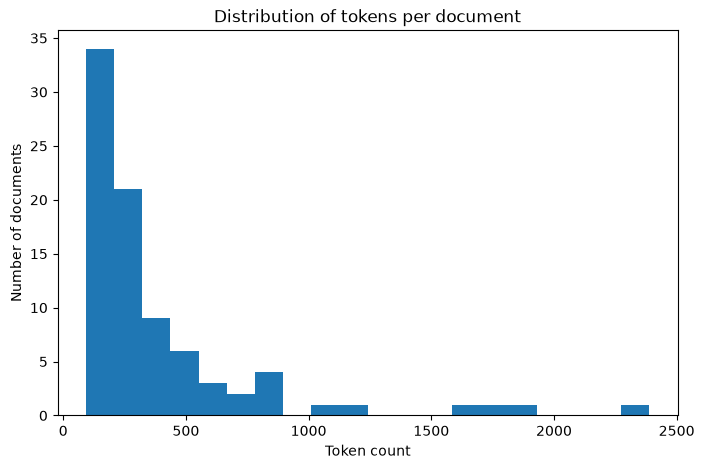

In [9]:
#Distribution of tokens per document
plt.figure(figsize=(8, 5))
plt.hist(token_counts, bins=20)
plt.title("Distribution of tokens per document")
plt.xlabel("Token count")
plt.ylabel("Number of documents")
plt.show()

In [10]:
#Chunk statistics
chunk_token_counts = [c["token_count"] for c in chunks]

chunk_stats = {
    "num_chunks": len(chunks),
    "avg_tokens_per_chunk": round(mean(chunk_token_counts), 2) if chunk_token_counts else 0,
    "median_tokens_per_chunk": round(median(chunk_token_counts), 2) if chunk_token_counts else 0,
    "max_tokens_per_chunk": max(chunk_token_counts) if chunk_token_counts else 0,
    "min_tokens_per_chunk": min(chunk_token_counts) if chunk_token_counts else 0,
}

pd.DataFrame([chunk_stats])

,num_chunks,avg_tokens_per_chunk,median_tokens_per_chunk,max_tokens_per_chunk,min_tokens_per_chunk
0,387,110.2,120,120,31


In [11]:
#Chunks per source file
chunk_df = pd.DataFrame(chunks)
chunk_counts_by_file = chunk_df.groupby("source_file").size().reset_index(name="num_chunks")
chunk_counts_by_file.sort_values("num_chunks", ascending=False).head(15)

,source_file,num_chunks
0,cbe_cards_corpus.md,27
65,cleaned28_cbe_AwudeNiwaypdf3.md,21
66,cleaned28_cbe_AwudeNiwaypdf4.md,20
67,cleaned28_cbe_AwudeNiwaypdf5.md,18
72,cleaned28_nbe_extracted_doc_10.md,13
9,cleaned28_Press_Release_on_IDFR_307ddd5d1c_c5a...,12
8,cleaned28_Press_Release_2022_23_Half_Year_104e...,10
75,cleaned28_nbe_extracted_doc_13.md,10
62,cleaned28_cbe_AwudeNiwaypdf1.md,9
68,cleaned28_cbe_AwudeNiwaypdf7.md,9


C:\Users\ayish\AppData\Local\Temp\ipykernel_10576\3247239684.py:10: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


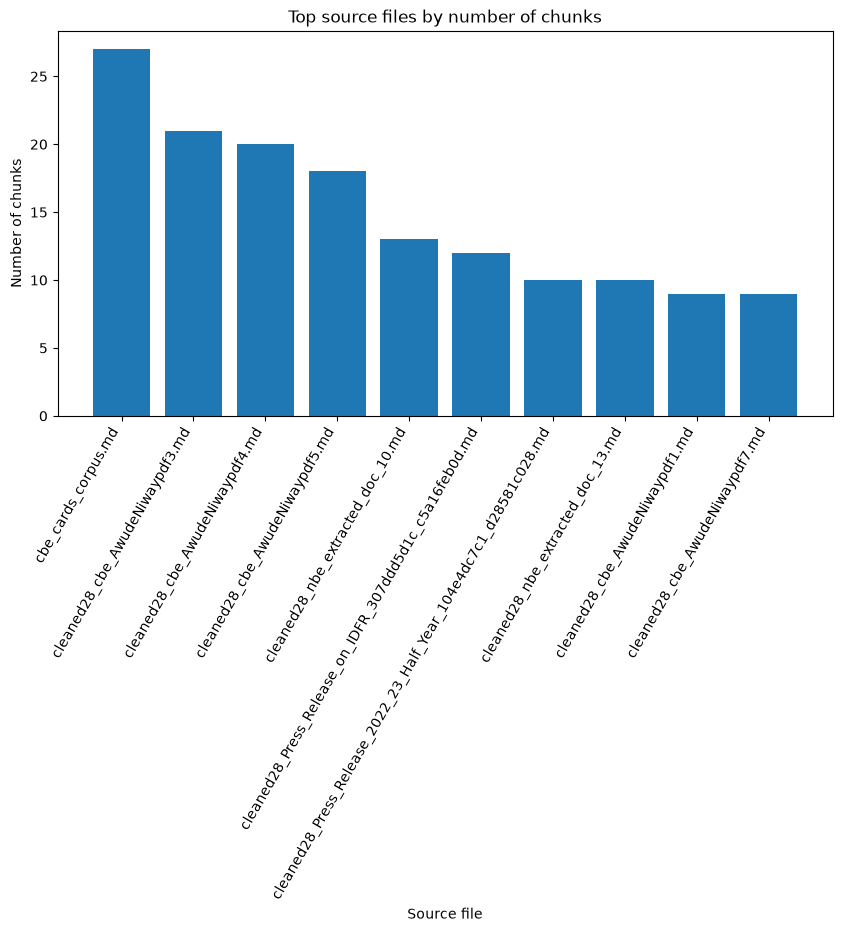

In [12]:
#Chunk count bar chart
top_files = chunk_counts_by_file.sort_values("num_chunks", ascending=False).head(10)

plt.figure(figsize=(10, 5))
plt.bar(top_files["source_file"], top_files["num_chunks"])
plt.xticks(rotation=60, ha="right")
plt.title("Top source files by number of chunks")
plt.xlabel("Source file")
plt.ylabel("Number of chunks")
plt.tight_layout()
plt.show()

In [13]:
#Sample chunk inspection
sample_chunk = chunks[0]

print("CHUNK ID:", sample_chunk["chunk_id"])
print("DOC ID:", sample_chunk["doc_id"])
print("SOURCE FILE:", sample_chunk["source_file"])
print("TOKEN COUNT:", sample_chunk["token_count"])
print("\n--- CHUNK TEXT ---\n")
print(sample_chunk["text"])

CHUNK ID: chunk_000001
DOC ID: doc_000001
SOURCE FILE: cbe_cards_corpus.md
TOKEN COUNT: 120

--- CHUNK TEXT ---

የኢትዮጵያ ንግድ ባንክ የካርድ አገልግሎቶች CBE Cards ለባንክ አገልግሎትዎ ምቾት ከአገር ውስጥ እና አለም አቀፍ የካርድ አገልግሎቶቻችን ይምረጡ --- ## 1 ስማርት የአገር ውስጥ ካርዶች Smart Domestic Cards ለቀላጠፈ የአገር ውስጥ ክፍያዎች ግብይቶች እና ለእለት ተእለት የባንክ አገልግሎት የተነደፉ ፈጣን ደህንነታቸው የተጠበቀ እና ተመጣጣኝ ካርዶች በድምሩ 8 የካርድ አማራጮች አሉ ### 1.1 ጠቅላላ አገልግሎት የሚሰጥ የቅድመ-ክፍያ ስጦታ ካርድ General Purpose Pre-Paid Gift Card መግለጫ እና ባህሪያት ካርዱ በጥሬ ገንዘብ በቼክ ወይም በስጦታ ሰርተፊኬት ምትክ ሊያገለግል ይችላል እንዲሁም በአሰሪዎች ዘንድ ለሰራተኞች ማበረታቻ ፕሮግራሞች እና/ወይም የማስተዋወቂያ ዘመቻ አካል ሆኖ ሊያገለግል ይችላል በካርዱ ላይ ሊጫን የሚችለው ከፍተኛው የገንዘብ መጠን 100,000 ብር ነው ከኤቲኤም ATM በቀን ሊወጣ የሚችለው ከፍተኛው የጥሬ ገንዘብ መጠን 5,000 ብር ነው በPOS ማሽን በቀን ሊፈፀም የሚችለው ከፍተኛው የክፍያ/የግዢ ገደብ በካርዱ


In [14]:
#Paper-ready summary table
paper_table = pd.DataFrame([
    {
        "Documents": len(tokenized_docs),
        "Total Tokens": sum(token_counts),
        "Avg Tokens / Document": round(mean(token_counts), 2) if token_counts else 0,
        "Chunks": len(chunks),
        "Avg Tokens / Chunk": round(mean(chunk_token_counts), 2) if chunk_token_counts else 0,
    }
])

paper_table

,Documents,Total Tokens,Avg Tokens / Document,Chunks,Avg Tokens / Chunk
0,85,33586,395.13,387,110.2
